# Bean Leaf Disease Classification – End-to-End ML Pipeline

**Author:** Yves Niyigena

Beans are a staple food crop in Rwanda and across East Africa. Two fungal diseases, **angular leaf spot** and **bean rust**, cause major yield losses, and smallholder farmers often lack quick access to an agronomist. This notebook builds an image classifier that tells, from a single photo of a bean leaf, whether it is:

| Class | Description |
|---|---|
| `angular_leaf_spot` | angular brown lesions bounded by leaf veins |
| `bean_rust` | many small reddish-brown pustules |
| `healthy` | no visible disease |

**Pipeline covered in this notebook**
1. Data acquisition
2. Exploratory analysis & feature interpretation (at least 3 features)
3. Data preprocessing
4. Model creation (transfer learning + optimisation techniques)
5. Model evaluation (accuracy, loss, precision, recall, F1, confusion matrix)
6. Model testing / prediction functions
7. Retraining with the saved model as the pre-trained model

In [1]:
import os, sys, json, random
sys.path.insert(0, os.path.abspath('..'))
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf

from src.preprocessing import (CLASS_NAMES, IMG_SIZE, TRAIN_DIR, TEST_DIR,
                               list_images, make_dataset, train_val_split, preprocess_image)
from src import model as M

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
COLORS = {'angular_leaf_spot': '#257de0', 'bean_rust': '#f47230', 'healthy': '#00b894'}
sns.set_theme(style='whitegrid')
print('TensorFlow', tf.__version__)

TensorFlow 2.18.0


## 1. Data acquisition

The data is the **iBeans** dataset collected in Uganda by the Makerere AI Lab with the National Crops Resources Research Institute (NaCRRI): field photos taken with smartphones. `src/data_acquisition.py` downloads the original train/validation/test zips from Hugging Face, merges train + validation into `data/train/` (we create our own validation split later), keeps the official test split in `data/test/`, and resizes every image once to 224×224.

In [2]:
from src import data_acquisition
if not os.path.isdir(TRAIN_DIR) or not os.listdir(TRAIN_DIR):
    data_acquisition.main()   # downloads + extracts (only needed on a fresh clone)

train_paths, train_labels = list_images(TRAIN_DIR)
test_paths, test_labels = list_images(TEST_DIR)
counts = pd.DataFrame({
    'train': pd.Series(train_labels).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    'test': pd.Series(test_labels).map(dict(enumerate(CLASS_NAMES))).value_counts(),
}).loc[CLASS_NAMES]
counts.loc['total'] = counts.sum()
counts

,train,test
angular_leaf_spot,389,43
bean_rust,393,43
healthy,385,42
total,1167,128


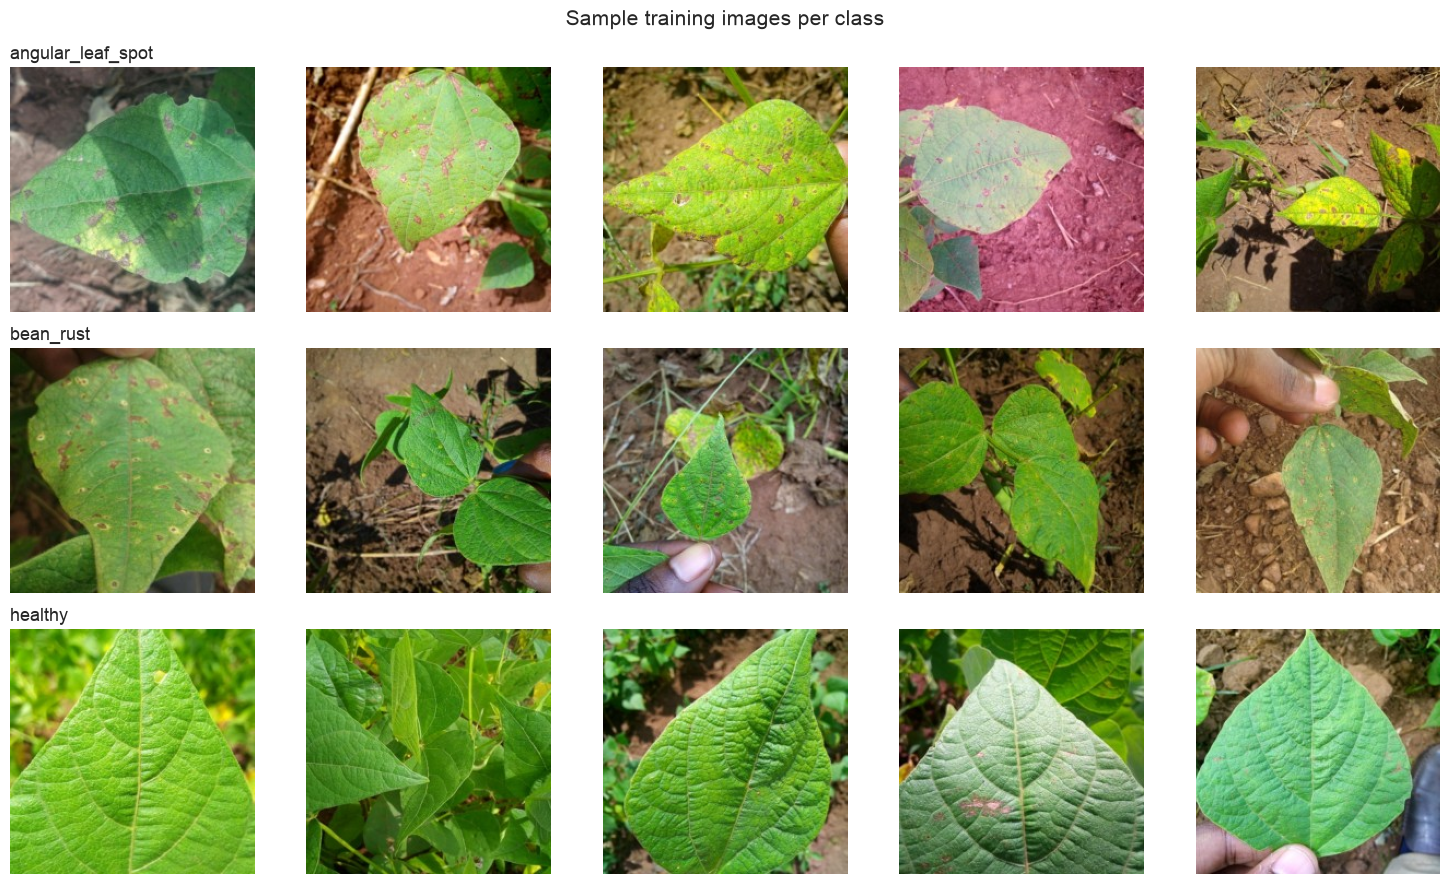

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, cls in enumerate(CLASS_NAMES):
    cls_paths = [p for p, y in zip(train_paths, train_labels) if y == row]
    for col, p in enumerate(random.sample(cls_paths, 5)):
        axes[row, col].imshow(Image.open(p)); axes[row, col].axis('off')
        if col == 0: axes[row, col].set_title(cls, loc='left', fontsize=13)
plt.suptitle('Sample training images per class', fontsize=15); plt.tight_layout(); plt.show()

## 2. Exploratory analysis – feature interpretation

A CNN learns its own features, but to understand the data we extract a few interpretable, hand-crafted image features (`src/insights.py`):

* **Greenness index** – mean of `G − (R+B)/2`: how much healthy green tissue is visible
* **Lesion ratio** – share of brown/yellow pixels (HSV hue 15–60°, saturated, not dark)
* **Edge density (texture)** – mean absolute pixel gradient
* **Mean R/G/B** and **brightness / contrast**

The same statistics are served by the API and drawn on the *Visualizations* page of the web app.

In [4]:
from src.insights import compute_insights
insights, rows = compute_insights()          # also writes models/insights.json for the UI
feat = pd.DataFrame(rows)
feat.groupby('label')[['greenness', 'lesion_ratio', 'edge_density', 'mean_r', 'mean_g', 'mean_b',
                       'brightness', 'contrast']].mean().round(3)

,greenness,lesion_ratio,edge_density,mean_r,mean_g,mean_b,brightness,contrast
label,,,,,,,,
angular_leaf_spot,33.445,0.315,10.398,128.382,134.458,73.642,125.708,40.770
bean_rust,19.659,0.236,10.824,121.409,119.703,78.678,115.536,41.839
healthy,39.321,0.110,10.896,120.697,142.672,86.006,129.642,41.186


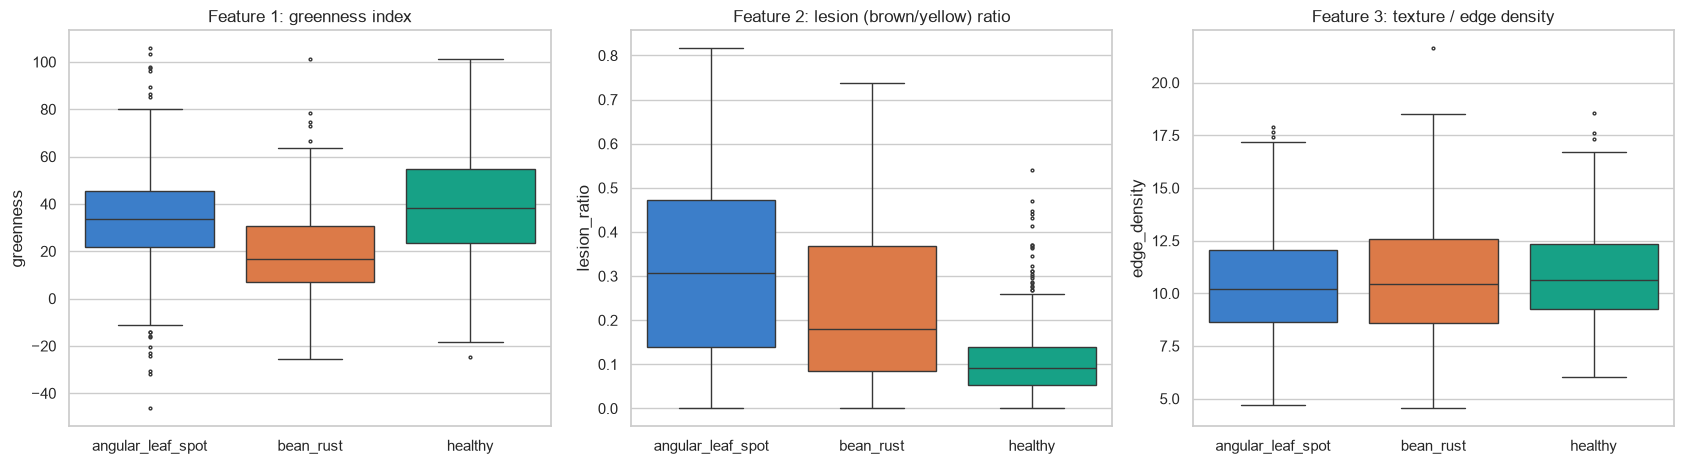

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (f, title) in zip(axes, [('greenness', 'Feature 1: greenness index'),
                                 ('lesion_ratio', 'Feature 2: lesion (brown/yellow) ratio'),
                                 ('edge_density', 'Feature 3: texture / edge density')]):
    sns.boxplot(data=feat, x='label', y=f, order=CLASS_NAMES, palette=COLORS, hue='label',
                legend=False, ax=ax, fliersize=2)
    ax.set_title(title); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Interpretation**

1. **Greenness** – healthy leaves are the greenest (≈39), angular leaf spot is slightly lower (≈33) and bean rust drops sharply (≈20). Both diseases destroy chlorophyll; rust's dense reddish-brown pustules remove the most green.
2. **Lesion ratio** – diseased leaves contain far more brown/yellow pixels (angular leaf spot ≈31%, bean rust ≈24%) than healthy leaves (≈11%). This is the clearest healthy-vs-diseased signal.
3. **Texture / edge density** – surprisingly, the *whole-image* edge density is almost identical across classes (≈10.4–10.9). Field photos include veins, soil and neighbouring leaves, so a global texture average hides the disease. The difference between the two diseases is *local* (many tiny rust pustules vs fewer, larger angular patches bounded by veins).

**Story:** colour features (greenness, lesion share) tell us *whether* a leaf is diseased, but global hand-crafted features cannot reliably tell *which* disease. That requires local patterns, exactly what convolutional filters learn. This motivates a CNN (transfer learning) rather than a model on colour statistics.

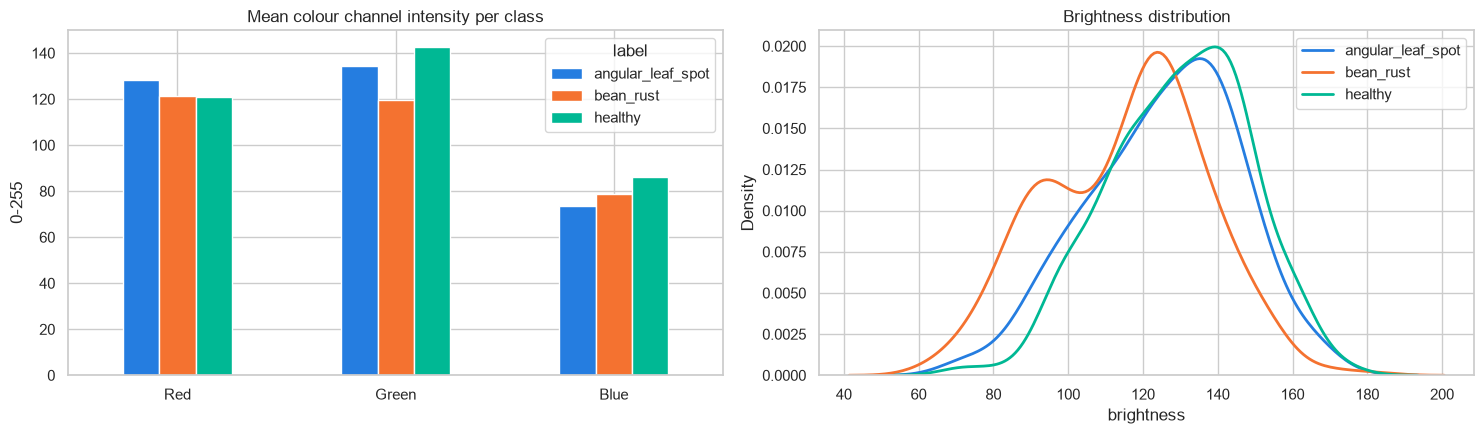

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
rgb = feat.groupby('label')[['mean_r', 'mean_g', 'mean_b']].mean().loc[CLASS_NAMES]
rgb.columns = ['Red', 'Green', 'Blue']
rgb.T.plot.bar(ax=axes[0], color=[COLORS[c] for c in CLASS_NAMES], rot=0)
axes[0].set_title('Mean colour channel intensity per class'); axes[0].set_ylabel('0-255')
for cls in CLASS_NAMES:
    sns.kdeplot(feat[feat.label == cls].brightness, ax=axes[1], color=COLORS[cls], label=cls, lw=2)
axes[1].set_title('Brightness distribution'); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation:** the green channel carries the signal: it falls from ≈142 (healthy) to ≈134 (angular leaf spot) and ≈119 (bean rust), while red stays flat or rises, so the red/green balance shifts toward yellow/brown. Brightness distributions overlap almost completely (bean rust photos are only slightly darker): photos were taken outdoors under varied light, so brightness is *not* predictive. This is why we use contrast augmentation, so the model does not latch onto lighting conditions.

## 3. Data preprocessing

Steps (implemented in `src/preprocessing.py`):

1. **Validation / decoding** – every file is opened with PIL / `tf.io.decode_image`, forced to 3-channel RGB; corrupt or non-image files are rejected.
2. **Resizing** – all images to **224×224**, the input size of MobileNetV2.
3. **Train / validation split** – stratified 85% / 15% split of `data/train` (seeded), so class balance is preserved. The official test split is never used for training or model selection.
4. **Scaling** – pixels rescaled from [0, 255] to [-1, 1] (MobileNetV2 convention). This is done by a `Rescaling` layer *inside* the model so serving code passes raw pixels and training/serving can never drift apart.
5. **Data augmentation** (training only, inside the model): random horizontal/vertical flips, rotation (±15%), zoom (±15%) and contrast (±15%). Leaves have no canonical orientation, and lighting varies in the field.
6. **Efficient input pipeline** – `tf.data` with parallel decoding, batching (32), shuffling and prefetching.

In [7]:
tr_p, va_p, tr_y, va_y = train_val_split(train_paths, train_labels, val_fraction=0.15)
print(f'train: {len(tr_p)}  validation: {len(va_p)}  test: {len(test_paths)}')
train_ds = make_dataset(tr_p, tr_y, batch_size=32, shuffle=True)
val_ds = make_dataset(va_p, va_y, batch_size=32)
test_ds = make_dataset(test_paths, test_labels, batch_size=32)
xb, yb = next(iter(train_ds))
print('batch', xb.shape, xb.dtype, 'pixel range', float(tf.reduce_min(xb)), '-', float(tf.reduce_max(xb)))

train: 991  validation: 176  test: 128
batch (32, 224, 224, 3) <dtype: 'float32'> pixel range 0.0 - 255.0


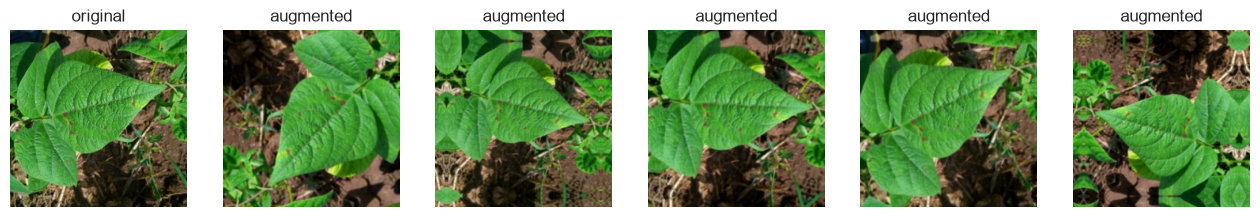

In [8]:
# Visualise the augmentation applied during training
aug = tf.keras.Sequential([tf.keras.layers.RandomFlip('horizontal_and_vertical'),
                           tf.keras.layers.RandomRotation(0.15), tf.keras.layers.RandomZoom(0.15),
                           tf.keras.layers.RandomContrast(0.15)])
img = preprocess_image(tr_p[0])
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(img.astype('uint8')); axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(np.clip(aug(img[None], training=True)[0].numpy(), 0, 255).astype('uint8')); ax.set_title('augmented')
for ax in axes: ax.axis('off')
plt.show()

## 4. Model creation

**Architecture** – transfer learning with **MobileNetV2** pre-trained on ImageNet (small and fast enough for CPU serving in the cloud), followed by:
`GlobalAveragePooling → Dropout(0.3) → Dense(128, ReLU, L2=1e-4) → Dropout(0.3) → Dense(3, softmax, L2=1e-4)`

**Optimisation techniques used**
| Technique | Where |
|---|---|
| Pre-trained model (ImageNet MobileNetV2) | backbone |
| Data augmentation | in-model layers |
| Dropout + L2 regularisation | classification head |
| Adam optimiser | lr 1e-3 (head), 3e-5 (fine-tuning), 1e-5 (retraining) |
| Early stopping (`restore_best_weights`) | both phases |
| ReduceLROnPlateau | both phases |
| Two-phase training: frozen backbone, then fine-tuning the top ~55 layers with BatchNorm frozen | |

In [9]:
model = M.build_model()
model.summary(show_trainable=False)

Model: "bean_disease_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_to_minus1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
# Phase 1: train only the new classification head (backbone frozen)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=M.callbacks(), verbose=2)

Epoch 1/10


/Users/nives/ALU/Summative - MLOP/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


31/31 - 9s - 288ms/step - accuracy: 0.6448 - loss: 0.8683 - val_accuracy: 0.7955 - val_loss: 0.5398 - learning_rate: 0.0010


Epoch 2/10


31/31 - 7s - 237ms/step - accuracy: 0.7861 - loss: 0.5502 - val_accuracy: 0.8466 - val_loss: 0.4106 - learning_rate: 0.0010


Epoch 3/10


... (11 outputs left out)

Epoch 9/10


31/31 - 7s - 224ms/step - accuracy: 0.8718 - loss: 0.3521 - val_accuracy: 0.8977 - val_loss: 0.2623 - learning_rate: 0.0010


Epoch 10/10


31/31 - 9s - 282ms/step - accuracy: 0.8829 - loss: 0.3337 - val_accuracy: 0.8920 - val_loss: 0.2671 - learning_rate: 0.0010


In [11]:
# Phase 2: fine-tune the top of MobileNetV2 with a ~30x smaller learning rate (3e-5)
M.unfreeze_top(model)
M.compile_model(model, lr=M.FINETUNE_LR)
print('trainable weights:', len(model.trainable_weights))
h2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=M.callbacks(), verbose=2)

trainable weights: 22
Epoch 1/20


31/31 - 13s - 426ms/step - accuracy: 0.8658 - loss: 0.3704 - val_accuracy: 0.8920 - val_loss: 0.2629 - learning_rate: 3.0000e-05


Epoch 2/20


31/31 - 11s - 348ms/step - accuracy: 0.9021 - loss: 0.3011 - val_accuracy: 0.9091 - val_loss: 0.2277 - learning_rate: 3.0000e-05


Epoch 3/20


31/31 - 9s - 286ms/step - accuracy: 0.8951 - loss: 0.2714 - val_accuracy: 0.8977 - val_loss: 0.2314 - learning_rate: 3.0000e-05


... (18 outputs left out)

Epoch 13/20


31/31 - 9s - 288ms/step - accuracy: 0.9677 - loss: 0.1028 - val_accuracy: 0.9432 - val_loss: 0.1463 - learning_rate: 9.0000e-06


Epoch 14/20


31/31 - 9s - 282ms/step - accuracy: 0.9657 - loss: 0.1227 - val_accuracy: 0.9318 - val_loss: 0.1743 - learning_rate: 9.0000e-06


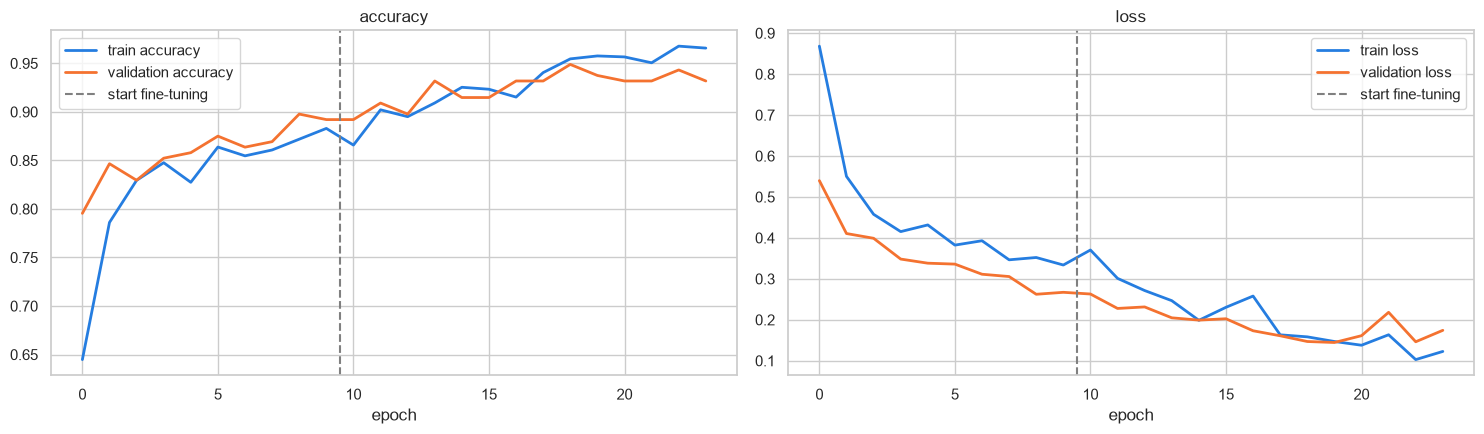

In [12]:
history = {k: h1.history[k] + h2.history.get(k, []) for k in ['loss', 'val_loss', 'accuracy', 'val_accuracy']}
history['phase_boundary'] = len(h1.history['loss'])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, m in zip(axes, ['accuracy', 'loss']):
    ax.plot(history[m], label=f'train {m}', color='#257de0', lw=2)
    ax.plot(history['val_' + m], label=f'validation {m}', color='#f47230', lw=2)
    ax.axvline(history['phase_boundary'] - 0.5, ls='--', color='gray', label='start fine-tuning')
    ax.set_xlabel('epoch'); ax.set_title(m); ax.legend()
plt.tight_layout(); plt.show()

## 5. Model evaluation on the held-out test set

We report **accuracy, loss (cross-entropy), precision, recall and F1-score** (macro-averaged over the classes), the per-class classification report and the confusion matrix.

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
metrics = M.evaluate(model)
summary = pd.Series({k: metrics[k] for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']}).round(4)
probs = model.predict(test_ds, verbose=0)
summary['roc_auc (ovr)'] = round(roc_auc_score(test_labels, probs, multi_class='ovr'), 4)
summary.to_frame('test set')

,test set
accuracy,0.9688
loss,0.1088
precision,0.9703
recall,0.9686
f1,0.9689
roc_auc (ovr),0.9980


                   precision    recall  f1-score   support

angular_leaf_spot     0.9348    1.0000    0.9663        43
        bean_rust     0.9762    0.9535    0.9647        43
          healthy     1.0000    0.9524    0.9756        42

         accuracy                         0.9688       128
        macro avg     0.9703    0.9686    0.9689       128
     weighted avg     0.9701    0.9688    0.9688       128



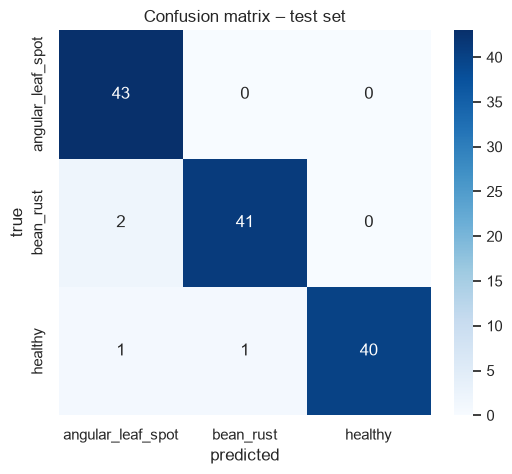

In [14]:
y_pred = probs.argmax(1)
print(classification_report(test_labels, y_pred, target_names=CLASS_NAMES, digits=4))
cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix – test set'); plt.show()

**Discussion:** the model reaches **96.9% accuracy, 0.969 macro F1 and 0.998 ROC-AUC** on 128 unseen test images; only 4 images are misclassified. Two bean-rust leaves are confused with angular leaf spot, consistent with the EDA (both diseases lower greenness and add brown tissue and differ mainly in lesion texture), and two healthy leaves (often with dust or shadows) are flagged as angular leaf spot. Importantly, healthy precision is 100%: **no diseased leaf was predicted as healthy**, so the model errs on the side of caution, which is the safer failure mode for a farmer.

## 6. Save the model
The model is saved in HDF5 format (`models/bean_disease_model.h5`) together with `models/model_metadata.json` (version, metrics, training history), which the API and UI read.

In [15]:
meta = M.save_model(model, metrics, history, trigger='initial (notebook)')
print('saved version', meta['version'], '->', M.MODEL_PATH, f'{os.path.getsize(M.MODEL_PATH)/1e6:.1f} MB')

saved version 1 -> /Users/nives/ALU/Summative - MLOP/models/bean_disease_model.h5 10.1 MB


## 7. Model testing – prediction functions

`src/prediction.py` exposes `predict_image(path | bytes)`, which reloads the saved model from disk, preprocesses one image and returns the label, confidence, class probabilities and agronomic advice. This is exactly what the `/predict` API endpoint calls.

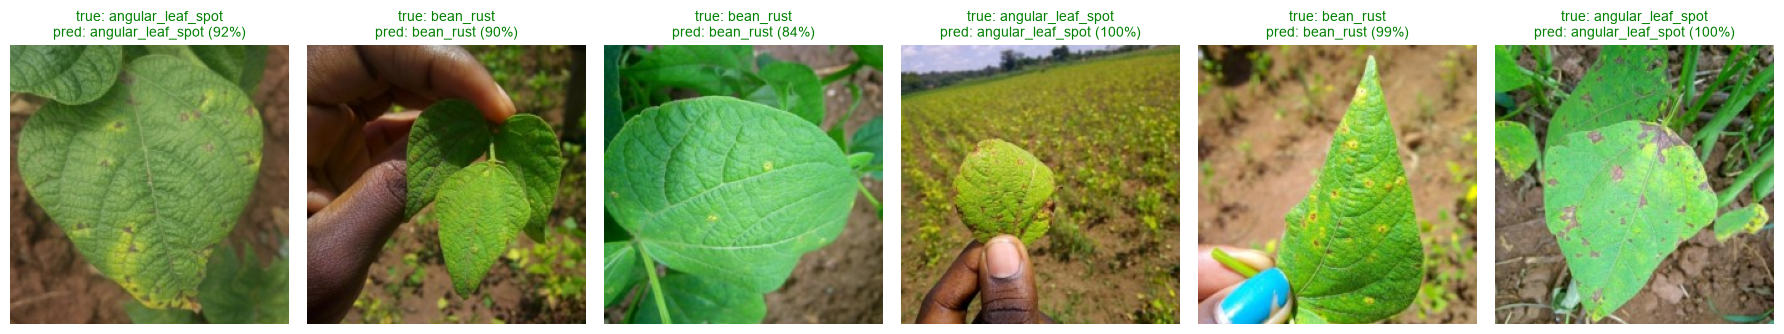

{
  "label": "angular_leaf_spot",
  "confidence": 0.9215943813323975,
  "probabilities": {
    "angular_leaf_spot": 0.9215943813323975,
    "bean_rust": 0.07836394757032394,
    "healthy": 4.180179166723974e-05
  },
  "advice": "Angular leaf spot (fungal). Remove infected leaves, rotate crops, use certified seed and consider a copper-based fungicide.",
  "model_version": 1,
  "inference_ms": 44.94
}


In [16]:
from src.prediction import Predictor
predictor = Predictor()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
sample = random.sample(list(zip(test_paths, test_labels)), 6)
for ax, (p, y) in zip(axes, sample):
    r = predictor.predict(p)
    ax.imshow(Image.open(p)); ax.axis('off')
    ok = r['label'] == CLASS_NAMES[y]
    ax.set_title(f"true: {CLASS_NAMES[y]}\npred: {r['label']} ({r['confidence']:.0%})", color='green' if ok else 'red', fontsize=10)
plt.tight_layout(); plt.show()
print(json.dumps(predictor.predict(sample[0][0]), indent=2))

## 8. Retraining

Retraining (`src/model.py::retrain`, orchestrated by `src/retrain.py`) is designed to run in production:

1. **Upload** – users upload bulk labelled images through the UI / `POST /upload`. Each file is validated, converted to RGB, resized and saved to `data/uploads/<label>/`, and a row is written to the SQLite database (`uploads` table).
2. **Preprocess** – the uploaded images go through the same `tf.data` preprocessing pipeline.
3. **Retrain** – the **currently deployed model is loaded as the pre-trained model** and fine-tuned (lr 1e-5, early stopping) on the new images plus a replay sample of the original training data (avoids catastrophic forgetting).
4. **Evaluate & promote** – the candidate is evaluated on the test set; it replaces the current model only if accuracy does not drop by more than 3 points. The old model is archived.
5. **Triggers** – a *Retrain* button (`POST /retrain`) and an automatic trigger when the number of pending uploads reaches a threshold (`RETRAIN_THRESHOLD`, default 30).

Below we simulate that flow with a handful of "new" images.

In [17]:
# simulate newly uploaded data: 10 images per class (in production these come from data/uploads)
new_p, new_y = [], []
for c in range(len(CLASS_NAMES)):
    idx = [i for i, y in enumerate(train_labels) if y == c]
    for i in random.sample(idx, 10):
        new_p.append(train_paths[i]); new_y.append(c)
result = M.retrain(new_p, new_y, epochs=2, replay_per_class=40, trigger='notebook demo')
print(json.dumps({k: v for k, v in result.items() if k != 'new_metrics'}, indent=2))
print({k: round(result['new_metrics'][k], 4) for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']})

/Users/nives/ALU/Summative - MLOP/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


{
  "promoted": true,
  "previous_accuracy": 0.96875,
  "n_new_samples": 30,
  "n_replay_samples": 120,
  "epochs_run": 2,
  "duration_sec": 6.4,
  "version": 2
}
{'accuracy': 0.9688, 'loss': 0.0897, 'precision': 0.9691, 'recall': 0.9688, 'f1': 0.9686}


## Conclusion

* A MobileNetV2 transfer-learning model with augmentation, dropout, L2, Adam, early stopping, LR scheduling and fine-tuning classifies bean leaves into 3 classes with high accuracy, precision, recall and F1 on an unseen test set.
* The EDA shows that colour features separate healthy from diseased leaves, and texture separates the two diseases.
* The model is saved (`models/bean_disease_model.h5`), served through a FastAPI service with a web UI, and can be retrained on newly uploaded data using itself as the pre-trained model.